# 11 · Speckle from random phase and propagation

Speckle appears when coherent light with spatially varying phase interferes after propagation. We create a smooth random phase screen, apply it to a Gaussian beam, and observe the granular intensity.

This is the package-user version: imports come first, and each operation is introduced when the physical question calls for it.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from topolino import propTF2


## 1. Prepare a 2D Gaussian field and random phase

A random phase screen models unresolved wavefront structure. Filtering the noise makes neighboring phase values correlated, as in a smooth aberration.

In [ ]:
rng = np.random.default_rng(7)
lambda_m = 500e-9
window_m = 2e-3
n = 256
x_m = np.linspace(-window_m/2, window_m/2, n, endpoint=False)
X, Y = np.meshgrid(x_m, x_m)
envelope = np.exp(-(X**2+Y**2)/(2*(300e-6)**2))
noise = rng.normal(size=(n,n))
noise_spectrum = np.fft.fft2(noise)
fx = np.fft.fftfreq(n, d=window_m/n)
FX,FY = np.meshgrid(fx,fx)
lowpass = np.exp(-(FX**2+FY**2)/(2*(2e4)**2))
phase = np.real(np.fft.ifft2(noise_spectrum*lowpass))
phase = phase/phase.std()*0.5


## 2. Propagate and inspect the speckle pattern

The phase-modulated field interferes with itself during propagation. Displaying the output intensity makes the contrast easier to inspect than a line plot.

In [ ]:
field0 = envelope*np.exp(1j*phase)
field_z = propTF2(field0, window_m, window_m, lambda_m, 0.08)


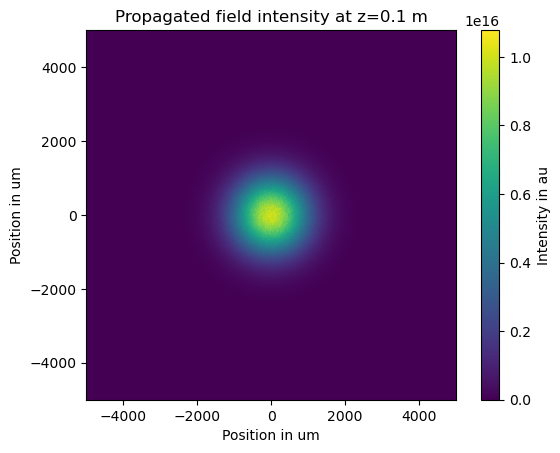

In [9]:
field = propTF(especkle, Dx_m, 500e-9, 0.1)
plt.imshow(np.abs(field)**2, extent=[x_m[0]*1e6, x_m[-1]*1e6, y_m[0]*1e6, y_m[-1]*1e6], origin='lower')
plt.xlabel("Position in um")
plt.ylabel("Position in um")
plt.title("Propagated field intensity at z=0.1 m")
plt.colorbar(label="Intensity in au")
plt.show()